# 클래스 불균형 처리
**Baseline과 같은 데이터·분할·CV·모델 설정에서 불균형 처리 방법만 바꿔 효과와 Trade-off를 비교합니다.**

| 항목 | 설정 |
|---|---|
| 비교 기준 | Baseline (불균형 처리 없음, 원래 분포 유지, `Taegyeom_baseline.ipynb`) |
| 모델 | Logistic Regression, Decision Tree, Random Forest, GBM, XGBoost, LightGBM (하이퍼파라미터는 Baseline과 동일한 기본값) |
| 방법 | ① **가중치만 변경** (Class Weight) ② **언더샘플링만 적용** (RandomUnderSampler) ③ **오버샘플링만 적용** (SMOTENC, 비교용 SMOTE) — 서로 섞지 않고 분리 실험 |
| 처리 강도 | 원래 분포 유지 → 부분 완화 → 균등화 (아래 2번에서 클래스별 목표 건수 명시) |
| 누수 방지 | 가중치는 **각 Training fold의 분포로 계산**, Sampling은 `imblearn` Pipeline 안에서 **Training fold에만 적용**. Validation fold·Test는 실제 분포 유지 |
| 검증 | Train 내부 `StratifiedKFold(5, shuffle=True, random_state=42)` + 상위 후보는 반복 층화 CV(5×3)로 재확인 |
| 핵심 지표 | Macro F1 (목표 ≥ 0.83), 클래스별 Precision·Recall, 놓침(소수→다수)·오경보(Other→소수) 건수 |

> Test 데이터는 이 노트북에서도 사용하지 않습니다.
>
> **실행 시간**: 실험(모델 × 조건 × fold)을 CPU 코어 수만큼 병렬로 실행합니다. 처음 실행 시 2코어 기준 약 6~7분(이전 순차 실행 대비 약 40% 단축), 코어가 많을수록 더 빠릅니다.
> 한 번 실행하면 결과가 `results/imbalance/Taegyeom_imbalance_runs.pkl`에 저장되고, 다음부터는 **`RERUN = False`(기본값) 상태에서 저장된 결과를 불러와 수 초 안에 끝납니다.** 실험 조건을 바꿨다면 `RERUN = True`로 바꿔 다시 실행하세요.

In [1]:
import sys, warnings, pickle, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, MINORITY_CLASSES, DISCRETE_FEATURES, make_pipeline, make_sampling_pipeline,
                         discrete_indices, LabelEncodedClassifier, class_weight_dict, under_strategy, over_strategy,
                         target_counts, run_many, summarize_runs, per_class_report, confusion_df, key_error_counts)

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC, SMOTE

RESULT_DIR = PROJECT_ROOT / "results" / "imbalance"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

# ---- 시각화 공통 스타일 ----
BLUE, BLUE_LIGHT, ORANGE, AQUA, RED, GRAY_MID = "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [RED, GRAY_MID, BLUE])   # 빨강 = 악화, 파랑 = 개선
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터 불러오기

In [2]:
X_train, X_test, y_train, y_test = load_data()   # X_test / y_test는 사용하지 않음
FEATURES = list(X_train.columns)
CAT_IDX = discrete_indices(FEATURES)                 # 전처리 후 이산형 변수 위치 (SMOTENC 범주 지정)
print("X_train:", X_train.shape, "| SMOTENC 범주형 열:", DISCRETE_FEATURES, "→ 전처리 후 인덱스", CAT_IDX)

# CV 1번째 fold의 Training 부분 (설명용: 실제 실험에서는 매 fold마다 해당 fold 분포로 다시 계산)
tr0, va0 = next(CV.split(X_train, y_train))
y_fold = y_train.iloc[tr0]
pd.DataFrame({"Train 전체": y_train.value_counts(), "Training fold 1": y_fold.value_counts(),
              "Validation fold 1": y_train.iloc[va0].value_counts()}).reindex(CLASS_ORDER).T

X_train: (1552, 26) | SMOTENC 범주형 열: ['TypeOfSteel_A300', 'Outside_Global_Index'] → 전처리 후 인덱스 [24, 25]


target,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
Train 전체,538,321,313,152,126,58,44
Training fold 1,430,257,250,122,101,46,35
Validation fold 1,108,64,63,30,25,12,9


## 2. 불균형 처리 방법 설계와 클래스별 목표 건수

### 선택한 방법과 이유
| 방법 | 동작 | 선택 이유 | 예상 위험 |
|---|---|---|---|
| **Class Weight** | 손실 함수에서 소수 클래스 오류에 큰 가중치. 데이터는 그대로 | 데이터 손실·합성 없이 모든 모델에 적용 가능하고 비용이 가장 낮음 | 소수 클래스 과다 예측 → 오경보 증가 |
| **Random Under Sampling** | 다수 클래스 행을 무작위 삭제 | 다수 클래스(Other_Faults·Bumps·K_Scratch) 편향을 직접 줄임 | Train이 1,242건(fold)뿐이라 **정보 손실**이 클 수 있음 |
| **SMOTENC** | 소수 클래스를 이웃 보간으로 합성. **범주형 열은 보간하지 않고 이웃 최빈값 사용** | 연속형·범주형(강종, Outside_Global_Index) 혼합 데이터에 맞는 SMOTE 계열 | 희소 클래스(약 35건)를 10배 이상 늘리면 **합성 표본 과적합** |
| SMOTE (비교용) | 모든 열을 연속형으로 보고 보간 | SMOTENC와의 차이를 보이기 위한 대조군 | 강종 0.37처럼 **존재할 수 없는 범주값** 생성 (3번에서 확인) |

- Random Over Sampling(단순 복제)은 SMOTE 계열과 역할이 겹치고, 같은 행이 여러 번 반복돼 과적합이 더 직접적이라 제외했습니다.
- 가중치 적용 인자: **LR·DT·RF는 `class_weight`**, sklearn GBM은 `class_weight` 인자가 없으므로 **GBM·XGBoost·LightGBM은 학습용 `sample_weight`** 로 설계했습니다(두 방식은 같은 손실 가중을 줌).
- SMOTENC 이웃 수 `k_neighbors=5`: 가장 희소한 Dirtiness가 Training fold에 약 35건이므로 5개 이웃을 안정적으로 찾을 수 있습니다(이웃 수 < 표본 수).

### 처리 강도 — 최대/최소 클래스 비율(IR) 기준으로 통일
원래 Training fold의 최대/최소 비율은 약 **12.2배**입니다. 세 방법 모두 이 비율을 같은 단계로 낮추도록 설계해 강도별로 직접 비교할 수 있게 했습니다.

| 단계 | Class Weight | Random Under Sampling | SMOTENC |
|---|---|---|---|
| 원래 분포 유지 | 가중치 없음 (Baseline) | 적용 안 함 | 적용 안 함 |
| 부분 완화 (약) | — | 다수 클래스를 **최소 클래스의 7배**로 축소 (IR ≤ 7) | 소수 클래스를 **최대 클래스의 1/7**까지 증강 (IR ≤ 7) |
| 부분 완화 | **α = 0.5**: w = (n_max/n_c)^0.5 | IR ≤ 3.5 | IR ≤ 3.5 |
| 균등화 | **α = 1**: w = n_max/n_c (= `balanced`) | IR = 1 (모든 클래스 = 최소 클래스 건수) | IR = 1 (모든 클래스 = 최대 클래스 건수) |

In [3]:
levels = [("원래 분포", "none", None), ("CW α=0.5", "weight", 0.5), ("CW α=1", "weight", 1.0),
          ("RUS IR≤7", "under", 7), ("RUS IR≤3.5", "under", 3.5), ("RUS IR=1", "under", 1),
          ("SMOTENC IR≤7", "over", 7), ("SMOTENC IR≤3.5", "over", 3.5), ("SMOTENC IR=1", "over", 1)]
tc = {}
for name, kind, v in levels:
    if kind == "weight":
        tc[name] = target_counts(y_fold, "weight", alpha=v)
    elif kind in ("under", "over"):
        tc[name] = target_counts(y_fold, kind, ir=v)
    else:
        tc[name] = target_counts(y_fold, "none")
tc = pd.DataFrame(tc).T[CLASS_ORDER]
tc["합계"] = tc.sum(axis=1).round(0)
tc["최대/최소"] = (tc[CLASS_ORDER].max(axis=1) / tc[CLASS_ORDER].min(axis=1)).round(2)
tc.to_csv(RESULT_DIR / "Taegyeom_imbalance_target_counts_fold1.csv")
print("Training fold 1 기준 처리 후 클래스별 건수 (Class Weight는 '건수 × 가중치' = 유효 건수)")
display(tc)

wt = pd.DataFrame({f"α={a}": pd.Series(class_weight_dict(y_fold, a)) for a in (0.5, 1.0)}).reindex(CLASS_ORDER).round(2).T
print("클래스 가중치 (최다 클래스 Other_Faults = 1)"); wt

Training fold 1 기준 처리 후 클래스별 건수 (Class Weight는 '건수 × 가중치' = 유효 건수)


,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,합계,최대/최소
원래 분포,430.0,257.0,250.0,122.0,101.0,46.0,35.0,1241.0,12.29
CW α=0.5,430.0,332.4,327.9,229.0,208.4,140.6,122.7,1791.0,3.50
CW α=1,430.0,430.0,430.0,430.0,430.0,430.0,430.0,3010.0,1.00
RUS IR≤7,245.0,245.0,245.0,122.0,101.0,46.0,35.0,1039.0,7.00
RUS IR≤3.5,122.0,122.0,122.0,122.0,101.0,46.0,35.0,670.0,3.49
RUS IR=1,35.0,35.0,35.0,35.0,35.0,35.0,35.0,245.0,1.00
SMOTENC IR≤7,430.0,257.0,250.0,122.0,101.0,61.0,61.0,1282.0,7.05
SMOTENC IR≤3.5,430.0,257.0,250.0,123.0,123.0,123.0,123.0,1429.0,3.50
SMOTENC IR=1,430.0,430.0,430.0,430.0,430.0,430.0,430.0,3010.0,1.00


클래스 가중치 (최다 클래스 Other_Faults = 1)


,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
α=0.5,1.0,1.29,1.31,1.88,2.06,3.06,3.51
α=1.0,1.0,1.67,1.72,3.52,4.26,9.35,12.29


**읽는 법**
- **RUS IR=1**은 모든 클래스를 Dirtiness 수준(35건)으로 줄여 Training fold가 **1,242건 → 245건(약 1/5)** 으로 줄어듭니다. Other_Faults는 430건 중 395건을 버립니다.
- **SMOTENC IR=1**은 모든 클래스를 Other_Faults 수준(430건)으로 늘려 **약 3,010건**이 되고, Dirtiness는 35건 → 430건으로 **합성 표본이 원본의 약 11배**입니다.
- **Class Weight α=1**은 행 수는 그대로 두고, Dirtiness 1건의 오류를 Other_Faults 1건의 약 12배로 계산합니다. 클래스별 유효 건수가 모두 같아집니다.

## 3. SMOTE vs SMOTENC — 범주형 변수 처리 확인

In [4]:
from Taegyeom_model_utils import build_preprocessor
prep = build_preprocessor(FEATURES).fit(X_train.iloc[tr0])
Xt = prep.transform(X_train.iloc[tr0]); names = list(prep.get_feature_names_out())
check = {}
for nm, sm in [("SMOTE", SMOTE(sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RANDOM_STATE)),
               ("SMOTENC", SMOTENC(categorical_features=CAT_IDX, sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RANDOM_STATE))]:
    Xs, ys = sm.fit_resample(Xt, y_fold)
    syn = pd.DataFrame(Xs[len(Xt):], columns=names)       # 합성된 행만
    check[nm] = {
        "합성 행 수": len(syn),
        "TypeOfSteel_A300 ∉ {0,1}": int((~syn["TypeOfSteel_A300"].isin([0, 1])).sum()),
        "Outside_Global_Index ∉ {0,0.5,1}": int((~syn["Outside_Global_Index"].isin([0, 0.5, 1])).sum()),
        "예: A300 고유값 수": syn["TypeOfSteel_A300"].nunique(),
    }
pd.DataFrame(check).T

,합성 행 수,"TypeOfSteel_A300 ∉ {0,1}","Outside_Global_Index ∉ {0,0.5,1}",예: A300 고유값 수
SMOTE,1769,234,379,228
SMOTENC,1769,0,0,2


- 일반 **SMOTE는 합성 행의 상당수에서 강종을 0~1 사이 실수(예: 0.37)로 만듭니다.** "A300이 37%인 강판"은 존재하지 않는 값입니다. Tree 모델은 이 값을 임계값으로 나눌 수 있어 결과가 나빠지지 않을 수도 있지만, **데이터 의미를 훼손**합니다.
- **SMOTENC는 범주형 열에 이웃의 최빈값을 사용**하므로 합성 행도 모두 유효한 범주값(0/1, 0/0.5/1)을 가집니다.
- 따라서 SMOTE 계열의 주 실험은 **SMOTENC**로 하고, 일반 SMOTE는 균등화(IR=1) 한 조건에서만 성능 비교용으로 둡니다.

## 4. 실험 실행 (6개 모델 × 10개 조건 = 60회 5-fold CV)

In [5]:
MODELS = {   # (모델 생성 함수, Scaling 여부, 가중치 적용 방식)
    "Logistic Regression": (lambda: LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), True, "class_weight"),
    "Decision Tree":       (lambda: DecisionTreeClassifier(random_state=RANDOM_STATE), False, "class_weight"),
    "Random Forest":       (lambda: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), False, "class_weight"),
    "GBM":                 (lambda: GradientBoostingClassifier(random_state=RANDOM_STATE), False, "sample_weight"),
    "XGBoost":             (lambda: LabelEncodedClassifier(XGBClassifier(random_state=RANDOM_STATE, n_jobs=1)), False, "sample_weight"),
    "LightGBM":            (lambda: LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), False, "sample_weight"),
}
METHODS = {
    "None":           dict(group="원래 분포", kind="none"),
    "CW α=0.5":       dict(group="가중치", kind="weight", alpha=0.5),
    "CW α=1":         dict(group="가중치", kind="weight", alpha=1.0),
    "RUS IR≤7":       dict(group="언더샘플링", kind="under", ir=7),
    "RUS IR≤3.5":     dict(group="언더샘플링", kind="under", ir=3.5),
    "RUS IR=1":       dict(group="언더샘플링", kind="under", ir=1),
    "SMOTENC IR≤7":   dict(group="오버샘플링", kind="smotenc", ir=7),
    "SMOTENC IR≤3.5": dict(group="오버샘플링", kind="smotenc", ir=3.5),
    "SMOTENC IR=1":   dict(group="오버샘플링", kind="smotenc", ir=1),
    "SMOTE IR=1":     dict(group="오버샘플링(비교)", kind="smote", ir=1),
}

def builder(make_model, scale, meth):
    k = meth["kind"]
    if k in ("none", "weight"):
        return lambda: make_pipeline(make_model(), FEATURES, scale=scale)
    if k == "under":
        mk = lambda: RandomUnderSampler(sampling_strategy=under_strategy(meth["ir"]), random_state=RANDOM_STATE)
    elif k == "smotenc":
        mk = lambda: SMOTENC(categorical_features=CAT_IDX, sampling_strategy=over_strategy(meth["ir"]), k_neighbors=5, random_state=RANDOM_STATE)
    else:
        mk = lambda: SMOTE(sampling_strategy=over_strategy(meth["ir"]), k_neighbors=5, random_state=RANDOM_STATE)
    return lambda: make_sampling_pipeline(make_model(), FEATURES, mk(), scale=scale)

RERUN = False                                   # True: 실험 다시 실행 / False: 저장된 결과가 있으면 불러오기
CACHE = RESULT_DIR / "Taegyeom_imbalance_runs.pkl"
specs = {(mname, meth_name): dict(build=builder(mk, scale, meth), weight_alpha=meth.get("alpha"), weight_mode=wmode)
         for mname, (mk, scale, wmode) in MODELS.items() for meth_name, meth in METHODS.items()}

t_all = time.perf_counter()
if CACHE.exists() and not RERUN:
    cache = pickle.load(open(CACHE, "rb")); runs = cache["runs"]
    print(f"저장된 결과를 불러왔습니다: {CACHE.name}")
else:
    runs = run_many(specs, X_train, y_train, n_jobs=-1)          # 60개 조건 × 5 fold = 300회 학습을 병렬 실행
    cache = {"runs": runs}; pickle.dump(cache, open(CACHE, "wb"))
for mname in MODELS:
    print(f"{mname:20s} | " + " | ".join(f"{me} {runs[(mname, me)]['folds']['val_macro_f1'].mean():.3f}" for me in METHODS))
print(f"\n소요 {time.perf_counter() - t_all:.0f}초")

저장된 결과를 불러왔습니다: Taegyeom_imbalance_runs.pkl
Logistic Regression  | None 0.719 | CW α=0.5 0.719 | CW α=1 0.672 | RUS IR≤7 0.716 | RUS IR≤3.5 0.681 | RUS IR=1 0.614 | SMOTENC IR≤7 0.715 | SMOTENC IR≤3.5 0.722 | SMOTENC IR=1 0.681 | SMOTE IR=1 0.684
Decision Tree        | None 0.721 | CW α=0.5 0.732 | CW α=1 0.711 | RUS IR≤7 0.696 | RUS IR≤3.5 0.703 | RUS IR=1 0.600 | SMOTENC IR≤7 0.738 | SMOTENC IR≤3.5 0.708 | SMOTENC IR=1 0.694 | SMOTE IR=1 0.692
Random Forest        | None 0.790 | CW α=0.5 0.786 | CW α=1 0.785 | RUS IR≤7 0.781 | RUS IR≤3.5 0.761 | RUS IR=1 0.666 | SMOTENC IR≤7 0.788 | SMOTENC IR≤3.5 0.791 | SMOTENC IR=1 0.795 | SMOTE IR=1 0.797
GBM                  | None 0.796 | CW α=0.5 0.801 | CW α=1 0.809 | RUS IR≤7 0.791 | RUS IR≤3.5 0.777 | RUS IR=1 0.676 | SMOTENC IR≤7 0.797 | SMOTENC IR≤3.5 0.806 | SMOTENC IR=1 0.806 | SMOTE IR=1 0.805
XGBoost              | None 0.811 | CW α=0.5 0.812 | CW α=1 0.809 | RUS IR≤7 0.810 | RUS IR≤3.5 0.774 | RUS IR=1 0.664 | SMOTENC IR≤7 0.802 | SM

In [6]:
# ---- 결과 정리 ----
summ = summarize_runs(list(runs.values()))
summ.index = pd.MultiIndex.from_tuples(list(runs.keys()), names=["model", "method"])
base_f1 = summ.xs("None", level="method")["macro_f1_mean"]
summ["delta_macro_f1"] = [summ.loc[(m, me), "macro_f1_mean"] - base_f1[m] for m, me in summ.index]

rows = []
for (m, me), r in runs.items():
    rep = per_class_report(y_train, r["oof"]); ke = key_error_counts(y_train, r["oof"])
    rows.append({"model": m, "method": me,
                 **{f"{c}_{k}": rep.loc[c, k] for c in CLASS_ORDER for k in ("precision", "recall", "f1")},
                 "놓침(소수→Other·Bumps)": ke.iloc[0], "오경보(Other→소수)": ke.iloc[1],
                 "Bumps↔Other": ke.iloc[2], "전체 오분류": ke.iloc[-1]})
detail = pd.DataFrame(rows).set_index(["model", "method"])

summ.to_csv(RESULT_DIR / "Taegyeom_imbalance_cv_summary.csv")
detail.to_csv(RESULT_DIR / "Taegyeom_imbalance_per_class_oof.csv")
pd.concat([r["folds"].assign(method=k[1], model=k[0]) for k, r in runs.items()]).to_csv(RESULT_DIR / "Taegyeom_imbalance_cv_folds.csv", index=False)
pd.concat([r["per_fold_class"].assign(method=k[1]) for k, r in runs.items()]).to_csv(RESULT_DIR / "Taegyeom_imbalance_per_fold_class.csv", index=False)
pd.DataFrame({f"{k[0]} | {k[1]}": r["oof"] for k, r in runs.items()}).assign(y_true=y_train).to_csv(RESULT_DIR / "Taegyeom_imbalance_oof_predictions.csv")

MODEL_NAMES, METHOD_NAMES = list(MODELS), list(METHODS)
tbl = summ["macro_f1_mean"].unstack("method").reindex(index=MODEL_NAMES, columns=METHOD_NAMES)
print("Macro F1 (5-fold 평균)"); display(tbl.round(4))
print("Baseline 대비 Macro F1 변화량"); display(summ["delta_macro_f1"].unstack("method").reindex(index=MODEL_NAMES, columns=METHOD_NAMES).round(4))

Macro F1 (5-fold 평균)


method,None,CW α=0.5,CW α=1,RUS IR≤7,RUS IR≤3.5,RUS IR=1,SMOTENC IR≤7,SMOTENC IR≤3.5,SMOTENC IR=1,SMOTE IR=1
model,,,,,,,,,,
Logistic Regression,0.7191,0.7188,0.6724,0.7164,0.6808,0.6143,0.7152,0.7221,0.6806,0.6840
Decision Tree,0.7207,0.7321,0.7108,0.6962,0.7033,0.5996,0.7385,0.7084,0.6942,0.6921
Random Forest,0.7899,0.7860,0.7853,0.7812,0.7613,0.6664,0.7879,0.7907,0.7955,0.7973
GBM,0.7963,0.8005,0.8095,0.7906,0.7768,0.6757,0.7973,0.8060,0.8062,0.8045
XGBoost,0.8109,0.8119,0.8091,0.8100,0.7744,0.6638,0.8018,0.8086,0.8201,0.8199
LightGBM,0.8044,0.8152,0.8137,0.8131,0.7770,0.6811,0.8092,0.8051,0.8268,0.8162


Baseline 대비 Macro F1 변화량


method,None,CW α=0.5,CW α=1,RUS IR≤7,RUS IR≤3.5,RUS IR=1,SMOTENC IR≤7,SMOTENC IR≤3.5,SMOTENC IR=1,SMOTE IR=1
model,,,,,,,,,,
Logistic Regression,0.0,-0.0003,-0.0468,-0.0027,-0.0383,-0.1048,-0.0039,0.0030,-0.0386,-0.0351
Decision Tree,0.0,0.0113,-0.0100,-0.0246,-0.0174,-0.1211,0.0177,-0.0124,-0.0266,-0.0286
Random Forest,0.0,-0.0039,-0.0046,-0.0086,-0.0286,-0.1234,-0.0020,0.0008,0.0056,0.0074
GBM,0.0,0.0043,0.0132,-0.0057,-0.0195,-0.1205,0.0010,0.0097,0.0099,0.0083
XGBoost,0.0,0.0009,-0.0019,-0.0009,-0.0366,-0.1471,-0.0091,-0.0024,0.0092,0.0089
LightGBM,0.0,0.0108,0.0093,0.0087,-0.0274,-0.1233,0.0048,0.0007,0.0224,0.0118


## 5. Baseline 대비 Macro F1 변화량

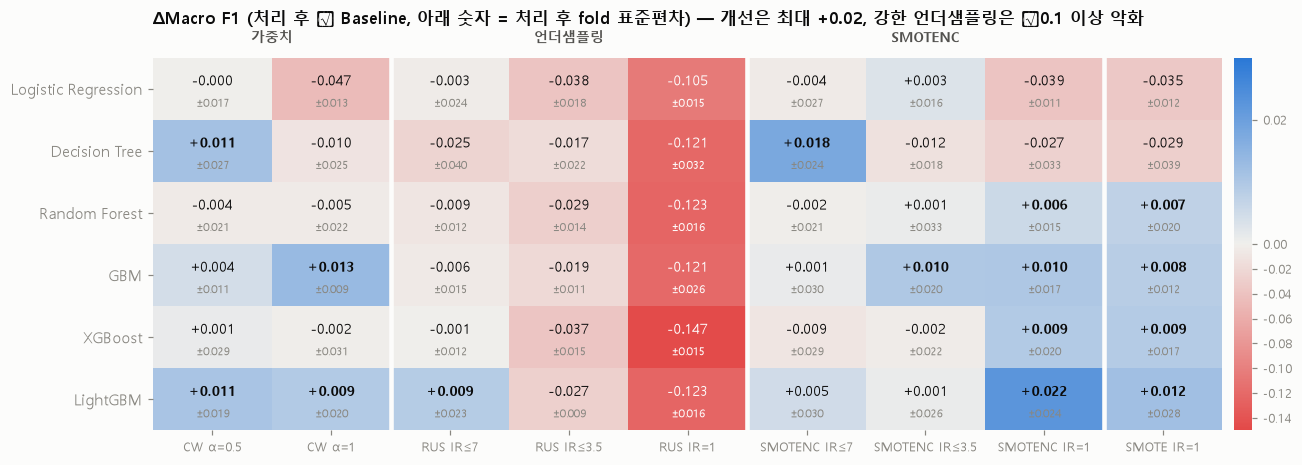

In [7]:
delta = summ["delta_macro_f1"].unstack("method").reindex(index=MODEL_NAMES, columns=METHOD_NAMES[1:])
std = summ["macro_f1_std"].unstack("method").reindex(index=MODEL_NAMES, columns=METHOD_NAMES[1:])
fig, ax = plt.subplots(figsize=(13, 4.4))
im = ax.imshow(delta.values, cmap=DIV, norm=TwoSlopeNorm(vmin=-0.15, vcenter=0, vmax=0.03), aspect="auto")
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        v = delta.values[i, j]
        ax.text(j, i - 0.12, f"{v:+.3f}", ha="center", va="center", fontsize=9, color="white" if v < -0.07 else INK,
                fontweight="bold" if v > 0.005 else None)
        ax.text(j, i + 0.24, f"±{std.values[i, j]:.3f}", ha="center", va="center", fontsize=7, color="white" if v < -0.07 else MUTED)
ax.set_xticks(range(delta.shape[1]), delta.columns, fontsize=8.5); ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
for x in (1.5, 4.5, 7.5): ax.axvline(x, color=SURFACE, lw=3)
for j, g in [(0.5, "가중치"), (3, "언더샘플링"), (6, "SMOTENC"), (8.6, "")]:
    ax.text(j, -0.75, g, ha="center", fontsize=9, color=INK2, fontweight="bold")
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
ax.set_title("ΔMacro F1 (처리 후 − Baseline, 아래 숫자 = 처리 후 fold 표준편차) — 개선은 최대 +0.02, 강한 언더샘플링은 −0.1 이상 악화", pad=22)
save(fig, "Taegyeom_imbalance_delta_macro_f1.png")

**해석 — 어떤 방법이 효과가 있었나**
- **개선 폭이 작습니다.** 가장 큰 개선도 LightGBM + SMOTENC 균등화 **+0.022**, RF·GBM·XGBoost의 최선도 +0.006 ~ +0.013입니다.
  이 값들은 대부분 **fold 간 표준편차(±0.01~0.03)보다 작거나 비슷**해 "확실한 개선"이라고 보기 어렵습니다(10번에서 반복 CV로 재확인).
- **언더샘플링은 강도가 높을수록 일관되게 악화**됩니다. IR≤7(약)까지는 ±0.01 이내지만, IR=1(균등화)은 모든 모델에서 **−0.10 ~ −0.15** 하락합니다(정보 손실, 9번).
- **SMOTENC는 Boosting·RF에서 강도를 높일수록 좋아지는 경향**(IR=1에서 최고)이 있지만, **LR·DT에서는 균등화가 오히려 악화**(−0.03 ~ −0.04)됩니다.
- **Class Weight**는 GBM(α=1, +0.013)·LightGBM(α=0.5, +0.011)에서 효과가 있지만, **LR α=1은 −0.047**로 크게 악화됩니다(7번에서 원인 분석).
- **SMOTE vs SMOTENC**: 성능 차이는 약 ±0.01로 비슷합니다. 성능보다 **범주값 유효성(3번)** 때문에 SMOTENC를 채택합니다.

## 6. 처리 강도에 따른 변화 (모델별)

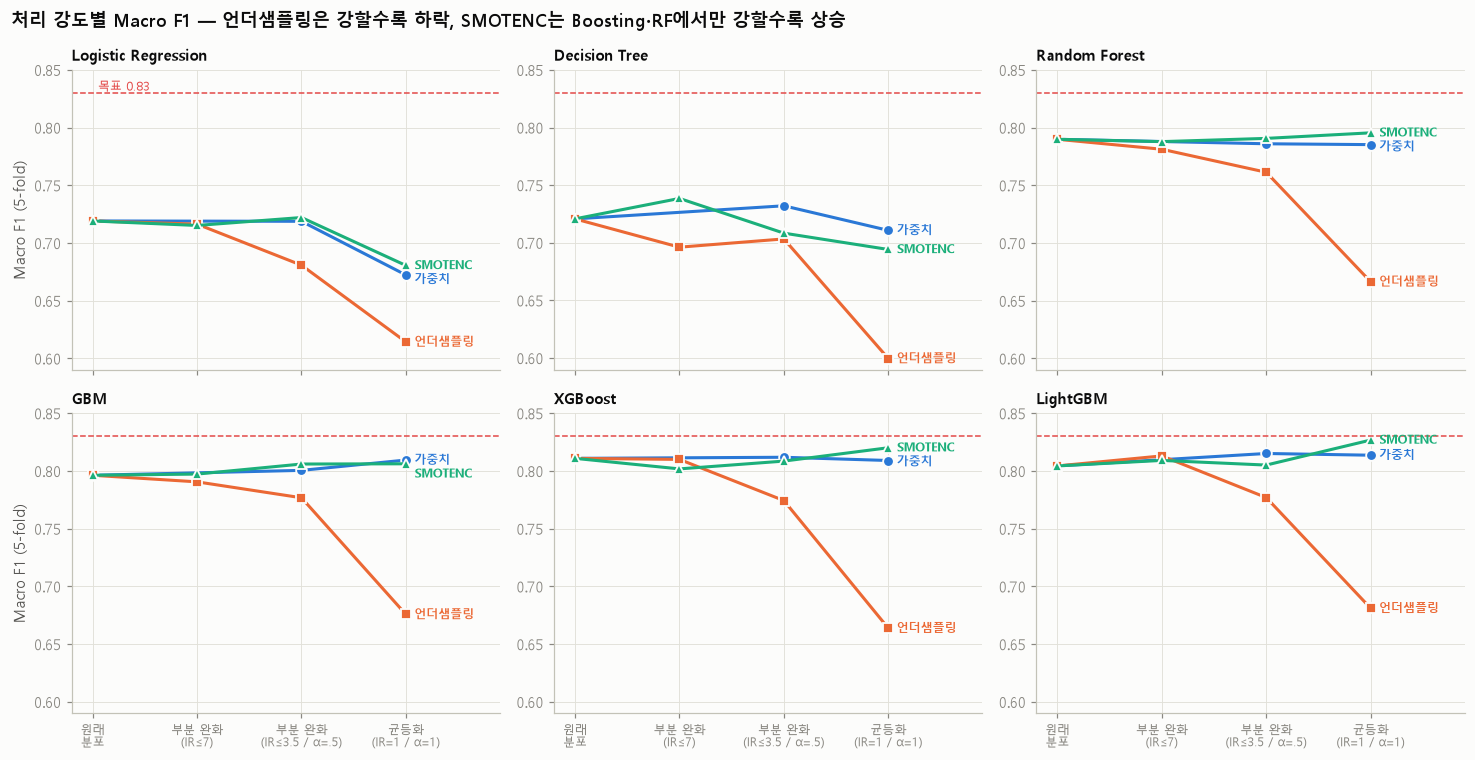

In [8]:
strength = {"가중치": ["None", "CW α=0.5", "CW α=1"],
            "언더샘플링": ["None", "RUS IR≤7", "RUS IR≤3.5", "RUS IR=1"],
            "SMOTENC": ["None", "SMOTENC IR≤7", "SMOTENC IR≤3.5", "SMOTENC IR=1"]}
xpos = {"None": 0, "CW α=0.5": 2, "CW α=1": 3, "RUS IR≤7": 1, "RUS IR≤3.5": 2, "RUS IR=1": 3,
        "SMOTENC IR≤7": 1, "SMOTENC IR≤3.5": 2, "SMOTENC IR=1": 3}
style = {"가중치": (BLUE, "o"), "언더샘플링": (ORANGE, "s"), "SMOTENC": (AQUA, "^")}
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7), sharex=True)
for ax, m in zip(axes.ravel(), MODEL_NAMES):
    ends = []
    for g, meths in strength.items():
        xs = [xpos[k] for k in meths]; ys = [summ.loc[(m, k), "macro_f1_mean"] for k in meths]
        c, mk = style[g]
        ax.plot(xs, ys, color=c, lw=2, marker=mk, ms=7, mec=SURFACE, mew=1.2, label=g)
        ends.append([ys[-1], g, c])
    ends.sort(key=lambda e: -e[0])                       # 끝점 라벨 겹침 방지 (최소 간격 0.012)
    for i in range(1, len(ends)):
        if ends[i - 1][0] - ends[i][0] < 0.012: ends[i][0] = ends[i - 1][0] - 0.012
    for yv, g, c in ends:
        ax.text(3.08, yv, g, color=c, fontsize=8, va="center", fontweight="bold")
    ax.axhline(0.83, color=RED, lw=1, ls="--")
    ax.set_title(m, fontsize=10); ax.set_xlim(-0.2, 3.9)
    ax.set_xticks([0, 1, 2, 3], ["원래\n분포", "부분 완화\n(IR≤7)", "부분 완화\n(IR≤3.5 / α=.5)", "균등화\n(IR=1 / α=1)"], fontsize=8)
    lo = min(summ.loc[m, "macro_f1_mean"].min(), 0.6); ax.set_ylim(lo - 0.01, 0.85)
axes[0, 0].text(0.05, 0.832, "목표 0.83", color=RED, fontsize=8)
for ax in axes[:, 0]: ax.set_ylabel("Macro F1 (5-fold)")
fig.suptitle("처리 강도별 Macro F1 — 언더샘플링은 강할수록 하락, SMOTENC는 Boosting·RF에서만 강할수록 상승", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_imbalance_strength_curves.png")

## 7. 클래스별 Precision · Recall 변화 (OOF)
불균형 처리의 목적은 소수 유형(특히 Baseline 최대 병목인 **Pastry**)의 Recall을 올리는 것이고, 대가는 Precision 하락과 다수 클래스(Other_Faults) Recall 하락입니다.

In [9]:
focus = ["Pastry", "Dirtiness", "Stains", "Other_Faults", "Bumps"]
pick = ["None", "CW α=1", "RUS IR≤7", "RUS IR=1", "SMOTENC IR≤3.5", "SMOTENC IR=1"]
for m in ["LightGBM", "XGBoost", "GBM", "Random Forest", "Logistic Regression"]:
    t = detail.loc[m].loc[pick, [f"{c}_{k}" for c in focus for k in ("recall", "precision")]]
    t.columns = pd.MultiIndex.from_tuples([(c, k[0].upper()) for c in focus for k in ("recall", "precision")])
    t[("Macro", "F1")] = summ.loc[m].loc[pick, "macro_f1_mean"]
    print(f"[{m}]  R = Recall, P = Precision"); display(t.round(3))

[LightGBM]  R = Recall, P = Precision


Pastry        Dirtiness        Stains        Other_Faults         Bumps         Macro
                    R      P         R      P      R      P            R      P      R      P     F1
method                                                                                              
None            0.524  0.653     0.773  0.872  0.931  0.947        0.764  0.726  0.682  0.672  0.804
CW α=1          0.571  0.632     0.795  0.921  0.966  0.918        0.730  0.751  0.701  0.641  0.814
RUS IR≤7        0.643  0.583     0.750  0.917  0.948  0.948        0.662  0.802  0.794  0.639  0.813
RUS IR=1        0.722  0.419     0.841  0.446  0.966  0.757        0.411  0.699  0.595  0.546  0.681
SMOTENC IR≤3.5  0.571  0.661     0.750  0.846  0.931  0.947        0.755  0.733  0.685  0.657  0.805
SMOTENC IR=1    0.643  0.659     0.795  0.875  0.966  0.966        0.745  0.759  0.713  0.678  0.827

[XGBoost]  R = Recall, P = Precision


Pastry        Dirtiness        Stains        Other_Faults         Bumps         Macro
                    R      P         R      P      R      P            R      P      R      P     F1
method                                                                                              
None            0.508  0.627     0.795  0.921  0.931  0.947        0.771  0.733  0.682  0.670  0.811
CW α=1          0.611  0.626     0.818  0.783  0.931  0.931        0.721  0.748  0.704  0.661  0.809
RUS IR≤7        0.706  0.571     0.795  0.814  0.948  0.932        0.636  0.810  0.776  0.634  0.810
RUS IR=1        0.698  0.413     0.841  0.378  0.966  0.767        0.398  0.704  0.579  0.564  0.664
SMOTENC IR≤3.5  0.579  0.664     0.795  0.854  0.931  0.931        0.757  0.722  0.664  0.676  0.809
SMOTENC IR=1    0.643  0.633     0.818  0.818  0.966  0.933        0.732  0.773  0.717  0.689  0.820

[GBM]  R = Recall, P = Precision


Pastry        Dirtiness        Stains        Other_Faults         Bumps         Macro
                    R      P         R      P      R      P            R      P      R      P     F1
method                                                                                              
None            0.524  0.629     0.795  0.854  0.897  0.912        0.755  0.710  0.660  0.658  0.796
CW α=1          0.690  0.596     0.818  0.837  0.931  0.915        0.673  0.767  0.729  0.636  0.809
RUS IR≤7        0.627  0.556     0.795  0.795  0.914  0.883        0.641  0.784  0.754  0.607  0.791
RUS IR=1        0.643  0.422     0.864  0.447  0.914  0.746        0.435  0.641  0.611  0.543  0.676
SMOTENC IR≤3.5  0.587  0.638     0.818  0.857  0.931  0.964        0.743  0.705  0.642  0.644  0.806
SMOTENC IR=1    0.706  0.610     0.841  0.740  0.931  0.931        0.682  0.768  0.707  0.645  0.806

[Random Forest]  R = Recall, P = Precision


Pastry        Dirtiness        Stains        Other_Faults         Bumps         Macro
                    R      P         R      P      R      P            R      P      R      P     F1
method                                                                                              
None            0.500  0.685     0.773  0.895  0.914  0.930        0.766  0.686  0.654  0.665  0.790
CW α=1          0.698  0.524     0.841  0.771  0.931  0.857        0.615  0.775  0.748  0.627  0.785
RUS IR≤7        0.611  0.554     0.773  0.829  0.931  0.885        0.619  0.759  0.760  0.601  0.781
RUS IR=1        0.698  0.398     0.841  0.500  0.948  0.764        0.364  0.729  0.685  0.566  0.666
SMOTENC IR≤3.5  0.563  0.628     0.795  0.854  0.931  0.915        0.738  0.687  0.651  0.666  0.791
SMOTENC IR=1    0.667  0.542     0.864  0.809  0.931  0.900        0.660  0.762  0.726  0.645  0.795

[Logistic Regression]  R = Recall, P = Precision


Pastry        Dirtiness        Stains        Other_Faults         Bumps         Macro
                    R      P         R      P      R      P            R      P      R      P     F1
method                                                                                              
None            0.516  0.575     0.545  0.649  0.931  0.915        0.677  0.629  0.558  0.626  0.719
CW α=1          0.730  0.440     0.773  0.324  0.966  0.800        0.413  0.760  0.651  0.615  0.672
RUS IR≤7        0.627  0.545     0.636  0.583  0.966  0.862        0.485  0.694  0.723  0.569  0.716
RUS IR=1        0.675  0.411     0.818  0.300  0.983  0.663        0.279  0.718  0.626  0.552  0.614
SMOTENC IR≤3.5  0.548  0.570     0.773  0.479  0.966  0.875        0.651  0.649  0.548  0.629  0.722
SMOTENC IR=1    0.738  0.463     0.841  0.370  0.966  0.824        0.411  0.725  0.645  0.595  0.681

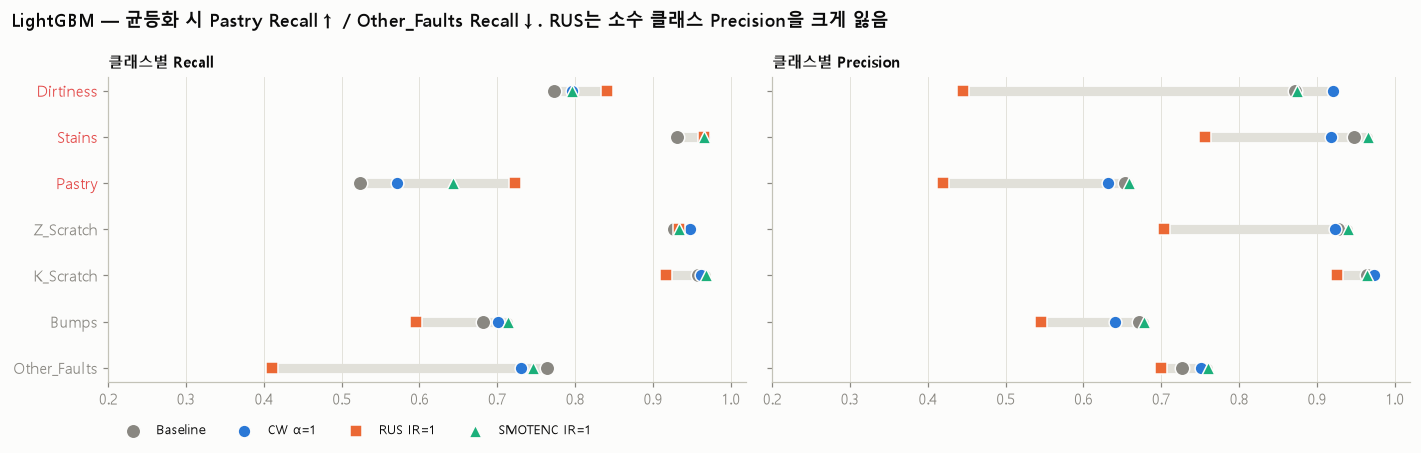

In [10]:
# 대표 모델(LightGBM) — Baseline vs 균등화 처리 3종의 클래스별 Recall/Precision 변화
m = "LightGBM"; comp = ["None", "CW α=1", "RUS IR=1", "SMOTENC IR=1"]
cols = {"None": MUTED, "CW α=1": BLUE, "RUS IR=1": ORANGE, "SMOTENC IR=1": AQUA}
marks = {"None": "o", "CW α=1": "o", "RUS IR=1": "s", "SMOTENC IR=1": "^"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, k in zip(axes, ["recall", "precision"]):
    for i, c in enumerate(CLASS_ORDER):
        vals = [detail.loc[(m, me), f"{c}_{k}"] for me in comp]
        ax.plot([min(vals), max(vals)], [i, i], color=GRID, lw=6, solid_capstyle="round", zorder=1)
        for me, v in zip(comp, vals):
            ax.scatter(v, i, s=70 if me != "None" else 90, color=cols[me], marker=marks[me], edgecolor=SURFACE, lw=1, zorder=3,
                       label=("Baseline" if me == "None" else me) if i == 0 else None)
    ax.set_yticks(range(7), CLASS_ORDER); ax.invert_yaxis(); ax.set_xlim(0.2, 1.02); ax.grid(axis="y", visible=False)
    ax.set_title(f"클래스별 {k.capitalize()}", fontsize=10)
    for lbl in ax.get_yticklabels():
        if lbl.get_text() in MINORITY_CLASSES: lbl.set_color(RED)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=4, frameon=False, fontsize=8.5)
fig.suptitle("LightGBM — 균등화 시 Pastry Recall↑ / Other_Faults Recall↓. RUS는 소수 클래스 Precision을 크게 잃음",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_imbalance_per_class_lightgbm.png")

**해석 — 개선된 클래스와 악화된 클래스**
- **Pastry Recall이 가장 크게 개선**됩니다. LightGBM 0.52 → 0.64(SMOTENC IR=1), XGBoost 0.51 → 0.64, GBM 0.52 → 0.69(CW α=1), RF 0.50 → 0.67(SMOTENC IR=1).
  Baseline에서 Other_Faults·Bumps로 흡수되던 Pastry가 일부 회복됩니다.
- **SMOTENC 균등화(Boosting)** 는 Pastry의 **Precision을 유지하면서 Recall을 올립니다**(LightGBM P 0.65 → 0.66). 그래서 F1이 실제로 오릅니다.
  반면 **RUS IR=1**은 Pastry Recall은 오르지만 Precision이 0.42로 떨어지고, **Dirtiness Precision이 0.87 → 0.45**로 반토막 나 오경보가 폭증합니다.
- **대가는 Other_Faults Recall 하락**입니다. LightGBM 0.76 → 0.75(SMOTENC)로 작지만, **RUS IR=1은 0.41**, **LR CW α=1은 0.68 → 0.41**로 크게 떨어집니다.
  LR α=1의 큰 악화는 선형 모델이 가중치에 맞춰 결정경계를 통째로 옮겨, 가장 큰 클래스인 Other_Faults를 대거 소수 유형으로 넘기기 때문입니다.
- **앙상블 기준 Stains·Dirtiness Recall은 이미 높아(0.77~0.93) 개선 여지가 작고**, 처리 강도를 높이면 Precision만 떨어지는 경우가 많습니다. 즉 **희소 클래스 = 개선 대상**이라는 일반론이 이 데이터에는 그대로 맞지 않습니다.

## 8. 주요 오분류 건수 변화 — 놓침 vs 오경보 Trade-off

In [11]:
ke = detail[["놓침(소수→Other·Bumps)", "오경보(Other→소수)", "Bumps↔Other", "전체 오분류"]].copy()
for m in ["LightGBM", "XGBoost", "GBM", "Random Forest"]:
    t = ke.loc[m].reindex(METHOD_NAMES).copy()
    t["Δ놓침"] = t.iloc[:, 0] - t.loc["None"].iloc[0]; t["Δ오경보"] = t.iloc[:, 1] - t.loc["None"].iloc[1]
    t["Δ전체"] = t["전체 오분류"] - t.loc["None", "전체 오분류"]
    print(f"[{m}] OOF 건수 (Train 1,552건)"); display(t)
ke.to_csv(RESULT_DIR / "Taegyeom_imbalance_key_errors_oof.csv")

[LightGBM] OOF 건수 (Train 1,552건)


,놓침(소수→Other·Bumps),오경보(Other→소수),Bumps↔Other,전체 오분류,Δ놓침,Δ오경보,Δ전체
method,,,,,,,
None,69,24,171,327,0,0,0
CW α=0.5,60,34,169,322,-9,10,-5
CW α=1,61,31,178,326,-8,7,-1
RUS IR≤7,53,43,167,323,-16,19,-4
RUS IR≤3.5,35,84,172,393,-34,60,66
RUS IR=1,32,124,200,527,-37,100,200
SMOTENC IR≤7,74,23,173,322,5,-1,-5
SMOTENC IR≤3.5,65,28,176,327,-4,4,0
SMOTENC IR=1,52,35,167,305,-17,11,-22


[XGBoost] OOF 건수 (Train 1,552건)


,놓침(소수→Other·Bumps),오경보(Other→소수),Bumps↔Other,전체 오분류,Δ놓침,Δ오경보,Δ전체
method,,,,,,,
None,71,26,172,319,0,0,0
CW α=0.5,60,33,181,327,-11,7,8
CW α=1,54,41,176,326,-17,15,7
RUS IR≤7,42,55,169,334,-29,29,15
RUS IR≤3.5,34,84,177,392,-37,58,73
RUS IR=1,32,130,183,543,-39,104,224
SMOTENC IR≤7,70,30,176,329,-1,4,10
SMOTENC IR≤3.5,61,31,178,327,-10,5,8
SMOTENC IR=1,49,39,156,307,-22,13,-12


[GBM] OOF 건수 (Train 1,552건)


,놓침(소수→Other·Bumps),오경보(Other→소수),Bumps↔Other,전체 오분류,Δ놓침,Δ오경보,Δ전체
method,,,,,,,
None,70,32,182,343,0,0,0
CW α=0.5,58,35,186,351,-12,3,8
CW α=1,45,46,178,338,-25,14,-5
RUS IR≤7,53,51,183,355,-17,19,12
RUS IR≤3.5,36,82,179,398,-34,50,55
RUS IR=1,40,114,215,543,-30,82,200
SMOTENC IR≤7,72,35,177,345,2,3,2
SMOTENC IR≤3.5,59,32,194,347,-11,0,4
SMOTENC IR=1,42,48,176,336,-28,16,-7


[Random Forest] OOF 건수 (Train 1,552건)


,놓침(소수→Other·Bumps),오경보(Other→소수),Bumps↔Other,전체 오분류,Δ놓침,Δ오경보,Δ전체
method,,,,,,,
None,75,23,183,354,0,0,0
CW α=0.5,62,44,179,363,-13,21,9
CW α=1,41,64,174,368,-34,41,14
RUS IR≤7,57,52,186,375,-18,29,21
RUS IR≤3.5,35,89,179,414,-40,66,60
RUS IR=1,32,128,180,550,-43,105,196
SMOTENC IR≤7,75,26,183,355,0,3,1
SMOTENC IR≤3.5,65,35,187,360,-10,12,6
SMOTENC IR=1,45,55,169,354,-30,32,0


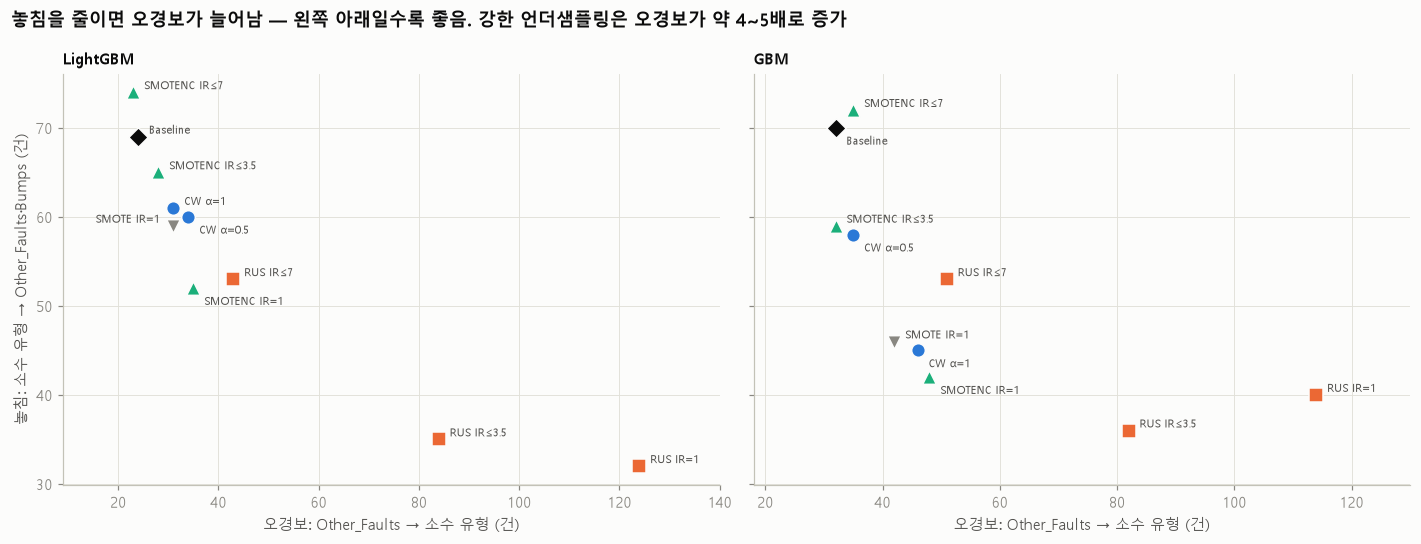

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
gcol = {"원래 분포": INK, "가중치": BLUE, "언더샘플링": ORANGE, "오버샘플링": AQUA, "오버샘플링(비교)": MUTED}
gmk = {"원래 분포": "D", "가중치": "o", "언더샘플링": "s", "오버샘플링": "^", "오버샘플링(비교)": "v"}
for ax, m in zip(axes, ["LightGBM", "GBM"]):
    for me in METHOD_NAMES:
        g = METHODS[me]["group"]; xv, yv = ke.loc[(m, me)].iloc[1], ke.loc[(m, me)].iloc[0]
        ax.scatter(xv, yv, s=80, color=gcol[g], marker=gmk[g], edgecolor=SURFACE, lw=1, zorder=3)
    # 라벨 겹침 방지: 표시 좌표에서 이미 놓인 라벨과 겹치면 위·아래로 이동
    xs_ = ke.loc[m].iloc[:, 1]; ax.set_xlim(xs_.min() - 14, xs_.max() + 16)
    fig.canvas.draw(); k_ = fig.dpi / 72                          # points → pixels
    pts = {me: ax.transData.transform((ke.loc[(m, me)].iloc[1], ke.loc[(m, me)].iloc[0])) for me in METHOD_NAMES}
    placed = [(px - 6 * k_, py - 6 * k_, px + 6 * k_, py + 6 * k_) for px, py in pts.values()]   # 마커 영역
    for me in sorted(METHOD_NAMES, key=lambda k: -ke.loc[(m, k)].iloc[0]):
        px, py = pts[me]; lab = me.replace("None", "Baseline"); w = 4.4 * len(lab) * k_; h = 9 * k_
        for dx, dy in [(7, 2), (7, -11), (-7 - 4.4 * len(lab), 2), (-7 - 4.4 * len(lab), -11), (7, 12), (7, -21)]:
            box = (px + dx * k_, py + dy * k_, px + dx * k_ + w, py + dy * k_ + h)
            if all(box[2] < b_[0] or box[0] > b_[2] or box[3] < b_[1] or box[1] > b_[3] for b_ in placed): break
        placed.append(box)
        ax.annotate(lab, ax.transData.inverted().transform((px, py)), xytext=(dx, dy), textcoords="offset points", fontsize=7.5, color=INK2)
    ax.set_xlabel("오경보: Other_Faults → 소수 유형 (건)"); ax.set_title(m, fontsize=10)
axes[0].set_ylabel("놓침: 소수 유형 → Other_Faults·Bumps (건)")
fig.suptitle("놓침을 줄이면 오경보가 늘어남 — 왼쪽 아래일수록 좋음. 강한 언더샘플링은 오경보가 약 4~5배로 증가",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_imbalance_miss_vs_false_alarm.png")

**해석**
- 모든 방법이 **"놓침 ↓ ↔ 오경보 ↑"** 의 Trade-off 위에 있습니다.
  - LightGBM SMOTENC IR=1: 놓침 69 → 52건(−17), 오경보 24 → 35건(+11), **전체 오분류 327 → 305건(−22)**
  - GBM CW α=1: 놓침 70 → 45건(−25), 오경보 32 → 46건(+14), 전체 오분류 343 → 338건(−5)
  - RUS IR=1(앙상블): 놓침은 32~40건으로 줄지만 오경보가 114~130건으로 **약 3.5~5.5배** 늘어 전체 오분류가 약 200건 증가
- **현장 관점의 수용 가능성**: 문제 정의에서 놓침(원인 공정 신호 상실)을 더 중요하게 보았으므로, 놓침 1건을 줄이는 데 오경보 1건 이하가 늘어나는 방법
  (LightGBM·XGBoost SMOTENC IR=1, GBM CW α=1)은 수용 가능하다고 판단합니다. RF SMOTENC IR=1은 놓침 −30건 / 오경보 +32건으로 경계선입니다. 반대로 RUS IR=1은 놓침 30여 건을 줄이려고 오경보를 100건 가까이 늘리므로 **불필요한 점검 비용이 과도**합니다.
- **Bumps ↔ Other_Faults 혼동(약 160~180건)은 어떤 방법으로도 크게 줄지 않습니다.** 두 다수 클래스 간 경계 문제는 불균형 처리의 범위 밖입니다.

## 9. 과도한 처리의 부작용 — 언더샘플링 정보 손실 · 오버샘플링 과적합

In [14]:
side = summ[["n_train_after", "macro_f1_mean", "train_macro_f1", "overfit_gap", "accuracy_mean"]].copy()
side["Dirtiness_precision"] = detail["Dirtiness_precision"]; side["Stains_precision"] = detail["Stains_precision"]
order = ["None", "RUS IR≤7", "RUS IR≤3.5", "RUS IR=1", "SMOTENC IR≤7", "SMOTENC IR≤3.5", "SMOTENC IR=1"]
for m in ["LightGBM", "Decision Tree", "Logistic Regression"]:
    print(f"[{m}]"); display(side.loc[m].reindex(order).round(3))

[LightGBM]


,n_train_after,macro_f1_mean,train_macro_f1,overfit_gap,accuracy_mean,Dirtiness_precision,Stains_precision
method,,,,,,,
None,1241.6,0.804,1.000,0.196,0.789,0.872,0.947
RUS IR≤7,1043.0,0.813,0.961,0.147,0.792,0.917,0.948
RUS IR≤3.5,672.4,0.777,0.883,0.106,0.747,0.778,0.887
RUS IR=1,246.4,0.681,0.735,0.054,0.660,0.446,0.757
SMOTENC IR≤7,1282.8,0.809,1.000,0.191,0.793,0.921,0.964
SMOTENC IR≤3.5,1429.6,0.805,1.000,0.195,0.789,0.846,0.947
SMOTENC IR=1,3012.8,0.827,1.000,0.173,0.803,0.875,0.966


[Decision Tree]


,n_train_after,macro_f1_mean,train_macro_f1,overfit_gap,accuracy_mean,Dirtiness_precision,Stains_precision
method,,,,,,,
None,1241.6,0.721,1.000,0.279,0.707,0.667,0.844
RUS IR≤7,1043.0,0.696,0.945,0.249,0.685,0.633,0.847
RUS IR≤3.5,672.4,0.703,0.837,0.133,0.673,0.597,0.761
RUS IR=1,246.4,0.600,0.654,0.054,0.582,0.365,0.746
SMOTENC IR≤7,1282.8,0.738,1.000,0.262,0.718,0.694,0.857
SMOTENC IR≤3.5,1429.6,0.708,1.000,0.292,0.706,0.617,0.871
SMOTENC IR=1,3012.8,0.694,1.000,0.306,0.690,0.462,0.900


[Logistic Regression]


,n_train_after,macro_f1_mean,train_macro_f1,overfit_gap,accuracy_mean,Dirtiness_precision,Stains_precision
method,,,,,,,
None,1241.6,0.719,0.749,0.030,0.713,0.649,0.915
RUS IR≤7,1043.0,0.716,0.751,0.034,0.698,0.583,0.862
RUS IR≤3.5,672.4,0.681,0.708,0.027,0.660,0.493,0.778
RUS IR=1,246.4,0.614,0.625,0.011,0.608,0.300,0.663
SMOTENC IR≤7,1282.8,0.715,0.755,0.040,0.711,0.551,0.902
SMOTENC IR≤3.5,1429.6,0.722,0.748,0.026,0.712,0.479,0.875
SMOTENC IR=1,3012.8,0.681,0.705,0.024,0.668,0.370,0.824


**해석**
- **언더샘플링 정보 손실**: 학습 건수가 1,242 → 1,043(IR≤7) → 672(IR≤3.5) → **246(IR=1)** 으로 줄면서 Macro F1이 단조 감소합니다.
  Train-Validation 차이(overfit_gap)는 오히려 작아지는데, 이는 일반화가 좋아진 것이 아니라 **Train·Validation 모두에서 성능이 낮아진 과소적합**입니다.
  1,552건 규모의 작은 데이터에서 다수 클래스 행을 버리는 것은 비용이 큽니다.
- **오버샘플링 과적합**: SMOTENC IR=1은 Dirtiness를 약 11배로 합성합니다. Boosting은 여전히 개선되지만,
  - **Decision Tree**는 Train F1 ≈ 1.0을 유지한 채 Validation이 떨어져 **차이가 0.28 → 0.31로 커지고**, Dirtiness Precision이 0.67 → 0.46으로 하락합니다(합성 점 주변을 외워 실제 데이터에서 오경보).
  - **Logistic Regression**은 Dirtiness Precision이 0.65 → 0.37로 급락합니다. 합성 표본이 선형 경계를 소수 클래스 쪽으로 크게 끌어당긴 결과입니다.
- 결론적으로 **"강하게 처리할수록 좋다"는 성립하지 않으며**, 효과는 모델에 따라 반대 방향일 수도 있습니다.

## 10. 불확실성 확인 — 클래스별 fold 편차와 반복 층화 CV

In [15]:
pfc = pd.concat([r["per_fold_class"].assign(method=k[1]) for k, r in runs.items()])
unc = (pfc[pfc["class"].isin(["Pastry", "Stains", "Dirtiness"]) & pfc["method"].isin(["None", "SMOTENC IR=1", "CW α=1"])
           & pfc["model"].str.startswith("LightGBM")]
       .groupby(["method", "class"])["f1"].agg(["mean", "std", "min", "max"]).round(3))
print("LightGBM — 소수 클래스 F1의 fold 간 변동 (Validation fold당 Pastry ≈ 25건, Stains ≈ 12건, Dirtiness ≈ 9건)")
unc

LightGBM — 소수 클래스 F1의 fold 간 변동 (Validation fold당 Pastry ≈ 25건, Stains ≈ 12건, Dirtiness ≈ 9건)


mean    std    min    max
method       class                                
CW α=1       Dirtiness  0.847  0.085  0.714  0.947
             Pastry     0.596  0.082  0.478  0.691
             Stains     0.940  0.027  0.900  0.960
None         Dirtiness  0.816  0.070  0.714  0.889
             Pastry     0.575  0.136  0.381  0.750
             Stains     0.931  0.087  0.778  1.000
SMOTENC IR=1 Dirtiness  0.826  0.097  0.667  0.900
             Pastry     0.647  0.054  0.565  0.702
             Stains     0.964  0.041  0.900  1.000

In [16]:
# 상위 후보 4개(모델별 최고 처리)를 반복 층화 CV 5×3 = 15 fold로 Baseline과 '같은 fold'에서 짝지어 비교
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cand = {"Random Forest": "SMOTENC IR=1", "GBM": "CW α=1", "XGBoost": "SMOTENC IR=1", "LightGBM": "SMOTENC IR=1"}
rep_specs = {(m, mm): dict(build=builder(MODELS[m][0], MODELS[m][1], METHODS[mm]), weight_alpha=METHODS[mm].get("alpha"),
                           weight_mode=MODELS[m][2]) for m, me in cand.items() for mm in ["None", me]}
if "repeated" in cache and not RERUN:
    rep_runs = cache["repeated"]
else:
    rep_runs = run_many(rep_specs, X_train, y_train, cv=RCV, n_jobs=-1)   # 8개 조건 × 15 fold 병렬
    cache["repeated"] = rep_runs; pickle.dump(cache, open(CACHE, "wb"))
rep_rows = []
for m, me in cand.items():
    res = {mm: rep_runs[(m, mm)]["folds"]["val_macro_f1"].values for mm in ["None", me]}
    d = res[me] - res["None"]
    rep_rows.append({"model": m, "처리": me, "Baseline (5×3)": f"{res['None'].mean():.4f} ± {res['None'].std():.4f}",
                     "처리 후 (5×3)": f"{res[me].mean():.4f} ± {res[me].std():.4f}",
                     "ΔMacro F1 (짝 평균)": round(d.mean(), 4), "Δ 표준편차": round(d.std(ddof=1), 4),
                     "개선된 fold 수": f"{(d > 0).sum()}/15"})
rep_tbl = pd.DataFrame(rep_rows).set_index("model")
rep_tbl.to_csv(RESULT_DIR / "Taegyeom_imbalance_repeated_cv_check.csv")
rep_tbl

,처리,Baseline (5×3),처리 후 (5×3),ΔMacro F1 (짝 평균),Δ 표준편차,개선된 fold 수
model,,,,,,
Random Forest,SMOTENC IR=1,0.7885 ± 0.0259,0.8024 ± 0.0177,0.0138,0.0227,10/15
GBM,CW α=1,0.7994 ± 0.0238,0.8089 ± 0.0176,0.0095,0.0173,11/15
XGBoost,SMOTENC IR=1,0.8143 ± 0.0226,0.8151 ± 0.0195,0.0008,0.0160,6/15
LightGBM,SMOTENC IR=1,0.8101 ± 0.0270,0.8209 ± 0.0171,0.0108,0.0204,10/15


**해석**
- 희소 클래스의 F1은 **fold마다 크게 흔들립니다**(LightGBM Baseline Pastry F1 0.38~0.75)(Validation fold당 Dirtiness 약 9건, Stains 약 12건 → 1건 차이가 F1 약 0.05~0.1). 클래스별 소폭 개선·악화는 우연일 가능성이 큽니다.
- 반복 층화 CV(15 fold)로 재확인하면:
  - **RF + SMOTENC IR=1 (+0.014), LightGBM + SMOTENC IR=1 (+0.011), GBM + CW α=1 (+0.010)** 은 15 fold 중 10~11개에서 개선 → **작지만 방향은 일관**됩니다.
  - **XGBoost + SMOTENC IR=1은 +0.001(6/15 fold)로 사실상 효과 없음**입니다. 5-fold 한 번에서 보인 +0.009는 분할 운에 가까웠습니다.
  - LightGBM + SMOTENC의 반복 CV 평균은 0.821로, 단일 5-fold(0.827)보다 낮습니다. **목표 0.83은 불균형 처리만으로는 안정적으로 넘지 못합니다.**
- 처리 후 **표준편차가 줄어드는 것**(LightGBM 0.027 → 0.017, RF 0.026 → 0.018, LightGBM Pastry F1 fold 편차 0.136 → 0.054)은 소수 클래스 예측이 fold에 덜 민감해졌다는 의미로, 평균 개선보다 오히려 확실한 효과입니다.

## 11. 불균형 처리 전후 비교표 (모델별 최선 처리)

In [17]:
best_method = {}
for m in MODEL_NAMES:
    s = summ.loc[m].drop(index="None")
    s = s.drop(index="SMOTE IR=1")             # 범주값 훼손 → 채택 후보에서 제외
    best_method[m] = s["macro_f1_mean"].idxmax()

fmt = lambda m_, me, k: f"{summ.loc[(m_, me), k + '_mean']:.4f} ± {summ.loc[(m_, me), k + '_std']:.4f}"
rows = []
for m in MODEL_NAMES:
    for tag, me in [("적용 전", "None"), (f"적용 후 ({best_method[m]})", best_method[m])]:
        rows.append({"모델": m, "불균형 처리": tag, "Accuracy": fmt(m, me, "accuracy"),
                     "Precision (macro)": fmt(m, me, "macro_precision"), "Recall (macro)": fmt(m, me, "macro_recall"),
                     "F1 (weighted)": fmt(m, me, "weighted_f1"), "핵심 지표: Macro F1": fmt(m, me, "macro_f1"),
                     "ΔMacro F1": "" if me == "None" else f"{summ.loc[(m, me), 'delta_macro_f1']:+.4f}",
                     "Pastry Recall": f"{detail.loc[(m, me), 'Pastry_recall']:.3f}",
                     "놓침 / 오경보": f"{ke.loc[(m, me)].iloc[0]} / {ke.loc[(m, me)].iloc[1]}"})
compare = pd.DataFrame(rows).set_index(["모델", "불균형 처리"])
compare.to_csv(RESULT_DIR / "Taegyeom_imbalance_before_after_table.csv")
compare

Accuracy Precision (macro)   Recall (macro)    F1 (weighted)  핵심 지표: Macro F1 ΔMacro F1 Pastry Recall 놓침 / 오경보
모델                  불균형 처리                                                                                                                                      
Logistic Regression 적용 전                   0.7132 ± 0.0163   0.7324 ± 0.0245  0.7156 ± 0.0367  0.7104 ± 0.0161  0.7191 ± 0.0275                   0.516  72 / 47
                    적용 후 (SMOTENC IR≤3.5)  0.7120 ± 0.0242   0.7065 ± 0.0231  0.7517 ± 0.0116  0.7101 ± 0.0245  0.7221 ± 0.0164   +0.0030         0.548  54 / 64
Decision Tree       적용 전                   0.7075 ± 0.0170   0.7218 ± 0.0255  0.7288 ± 0.0273  0.7052 ± 0.0177  0.7207 ± 0.0259                   0.452  73 / 50
                    적용 후 (SMOTENC IR≤7)    0.7178 ± 0.0187   0.7357 ± 0.0155  0.7519 ± 0.0378  0.7156 ± 0.0177  0.7385 ± 0.0238   +0.0177         0.500  66 / 49
Random Forest       적용 전                   0.7719 ± 0.0153   0.8196 ± 0.0183  0.7718 ± 0.0404  0.7704 ± 0.0158  0.7899 ± 0.0312                   0.500  75 / 23
                    적용 후 (SMOTENC IR=1)    0.7719 ± 0.0143   0.7872 ± 0.0060  0.8118 ± 0.0285  0.7727 ± 0.0142  0.7955 ± 0.0150   +0.0056         0.667  45 / 55
GBM                 적용 전                   0.7790 ± 0.0086   0.8137 ± 0.0056  0.7852 ± 0.0189  0.7780 ± 0.0087  0.7963 ± 0.0101                   0.524  70 / 32
                    적용 후 (CW α=1)          0.7822 ± 0.0076   0.8085 ± 0.0157  0.8187 ± 0.0178  0.7829 ± 0.0063  0.8095 ± 0.0088   +0.0132         0.690  45 / 46
XGBoost             적용 전                   0.7945 ± 0.0171   0.8352 ± 0.0212  0.7997 ± 0.0397  0.7918 ± 0.0178  0.8109 ± 0.0308                   0.508  71 / 26
                    적용 후 (SMOTENC IR=1)    0.8022 ± 0.0094   0.8199 ± 0.0117  0.8270 ± 0.0305  0.8012 ± 0.0088  0.8201 ± 0.0202   +0.0092         0.643  49 / 39
LightGBM            적용 전                   0.7893 ± 0.0230   0.8266 ± 0.0252  0.7936 ± 0.0474  0.7875 ± 0.0237  0.8044 ± 0.0360                   0.524  69 / 24
                    적용 후 (SMOTENC IR=1)    0.8035 ± 0.0107   0.8370 ± 0.0146  0.8230 ± 0.0342  0.8032 ± 0.0112  0.8268 ± 0.0240   +0.0224         0.643  52 / 35

## 12. 혼동행렬 변화 — LightGBM: Baseline → SMOTENC 균등화

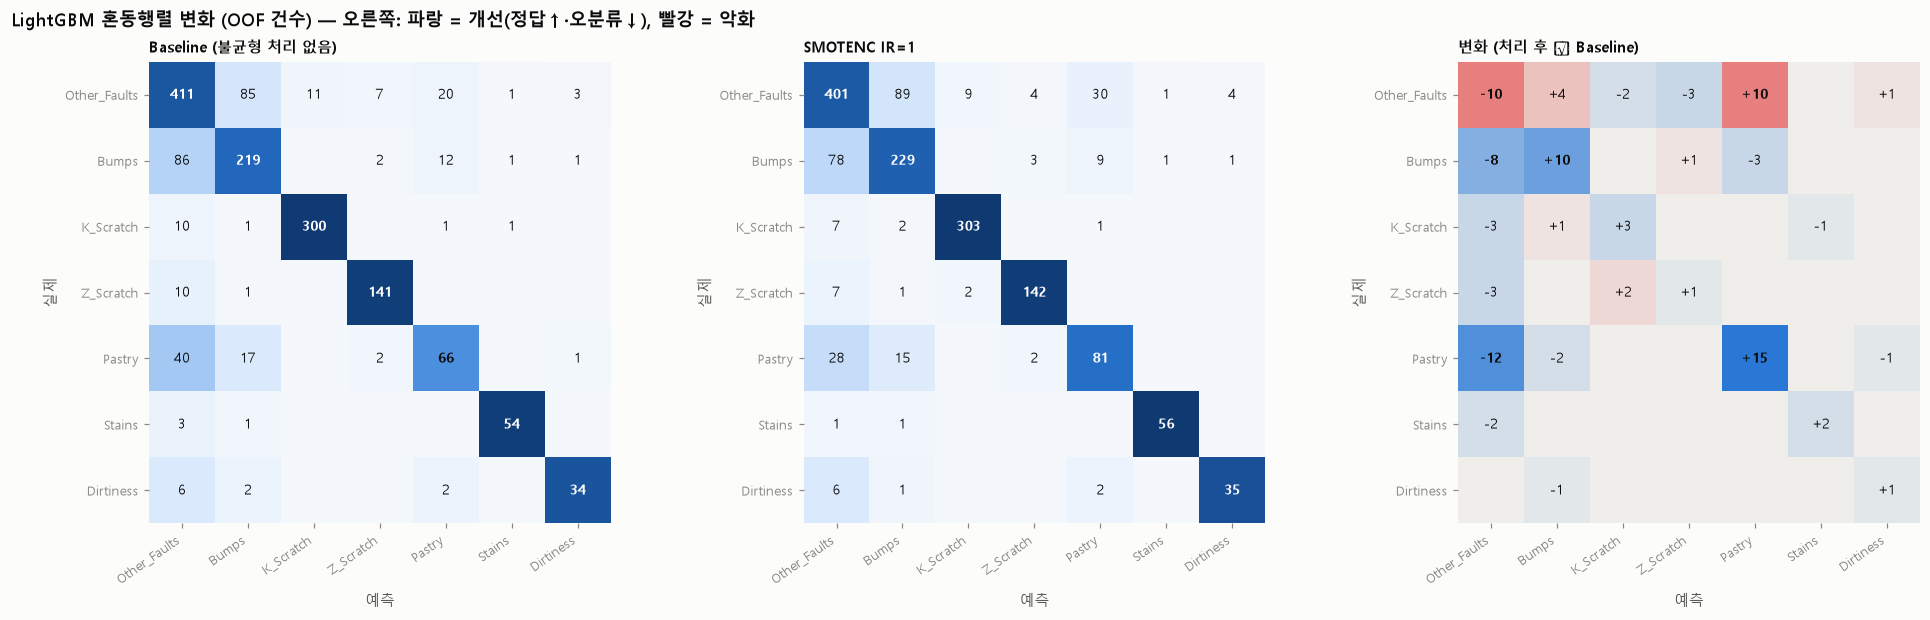

In [18]:
m, me = "LightGBM", "SMOTENC IR=1"
cb_, ca_ = confusion_df(y_train, runs[(m, "None")]["oof"]), confusion_df(y_train, runs[(m, me)]["oof"])
diff = ca_ - cb_
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, mat, ttl, kind in [(axes[0], cb_, "Baseline (불균형 처리 없음)", "cnt"), (axes[1], ca_, f"{me}", "cnt"),
                           (axes[2], diff, "변화 (처리 후 − Baseline)", "diff")]:
    if kind == "cnt":
        pct = mat.div(mat.sum(axis=1), axis=0) * 100
        ax.imshow(pct.values, cmap=SEQ, vmin=0, vmax=100)
        for i in range(7):
            for j in range(7):
                if mat.values[i, j]: ax.text(j, i, f"{mat.values[i, j]}", ha="center", va="center", fontsize=9,
                                             color="white" if pct.values[i, j] > 55 else INK, fontweight="bold" if i == j else None)
    else:
        v = diff.values.astype(float)
        # 대각선은 +가 개선, 비대각선은 −가 개선 → 개선 = 파랑으로 통일해 표시
        good = np.where(np.eye(7, dtype=bool), v, -v)
        ax.imshow(good, cmap=DIV, norm=TwoSlopeNorm(vmin=-15, vcenter=0, vmax=15))
        for i in range(7):
            for j in range(7):
                if v[i, j]: ax.text(j, i, f"{int(v[i, j]):+d}", ha="center", va="center", fontsize=9, color=INK,
                                    fontweight="bold" if abs(v[i, j]) >= 8 else None)
    ax.set_xticks(range(7), CLASS_ORDER, rotation=35, ha="right", fontsize=8.5); ax.set_yticks(range(7), CLASS_ORDER, fontsize=8.5)
    ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.grid(False); ax.set_title(ttl, fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("LightGBM 혼동행렬 변화 (OOF 건수) — 오른쪽: 파랑 = 개선(정답↑·오분류↓), 빨강 = 악화", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_imbalance_confusion_change_lightgbm.png")
diff.to_csv(RESULT_DIR / "Taegyeom_imbalance_confusion_diff_lightgbm.csv")

**해석**
- **Pastry 정답 +15건**: Pastry → Other_Faults 오분류가 12건 줄었습니다(Baseline 최대 병목 일부 해소).
- **Bumps 정답 +10건**: Bumps → Other_Faults 오분류가 8건 줄었습니다.
- **대가**: 실제 Other_Faults → Pastry 오분류가 **10건 늘어**(새 오경보의 대부분) Other_Faults 정답이 10건 줄었습니다. Other_Faults는 원래 다른 유형과 겹치는 "기타" 집합이라, 경계를 소수 쪽으로 옮기면 가장 먼저 손해를 봅니다.
- 전체 오분류는 327 → 305건으로 줄어, **Accuracy도 함께 개선**(0.789 → 0.803)되었습니다. 이 데이터에서는 불균형 처리가 반드시 Accuracy를 희생하지는 않았습니다.

## 13. 클래스 불균형 처리 결론 및 튜닝 후보 선정

In [19]:
final_pick = pd.DataFrame([
    ["LightGBM", "SMOTENC IR=1 (균등화)", "5-fold 최고 0.827, 반복 CV +0.011(10/15), 편차 감소, Accuracy 동반 개선", "1순위 튜닝 후보"],
    ["GBM", "Class Weight α=1 (sample_weight)", "반복 CV +0.010(11/15), 편차 최소, 합성 데이터 불필요", "안정성 후보"],
    ["XGBoost", "없음 또는 CW α=0.5", "SMOTENC 효과가 반복 CV에서 사라짐(+0.001) → 처리 방법도 튜닝 대상으로 포함", "튜닝 후보"],
    ["Random Forest", "SMOTENC IR=1", "반복 CV +0.014(10/15)로 개선폭 최대이나 절대 성능은 0.80", "비교 후보"],
    ["LR / Decision Tree", "—", "균등화 처리 시 악화. 처리해도 0.72~0.74", "비교 기준으로만 유지"],
], columns=["모델", "채택 불균형 처리", "근거", "튜닝 단계 역할"]).set_index("모델")
final_pick.to_csv(RESULT_DIR / "Taegyeom_imbalance_selection.csv")
final_pick

,채택 불균형 처리,근거,튜닝 단계 역할
모델,,,
LightGBM,SMOTENC IR=1 (균등화),"5-fold 최고 0.827, 반복 CV +0.011(10/15), 편차 감소, A...",1순위 튜닝 후보
GBM,Class Weight α=1 (sample_weight),"반복 CV +0.010(11/15), 편차 최소, 합성 데이터 불필요",안정성 후보
XGBoost,없음 또는 CW α=0.5,SMOTENC 효과가 반복 CV에서 사라짐(+0.001) → 처리 방법도 튜닝 대상...,튜닝 후보
Random Forest,SMOTENC IR=1,반복 CV +0.014(10/15)로 개선폭 최대이나 절대 성능은 0.80,비교 후보
LR / Decision Tree,—,균등화 처리 시 악화. 처리해도 0.72~0.74,비교 기준으로만 유지


| 질문 | 결과 |
|---|---|
| 어떤 클래스가 개선되었나 | **Pastry Recall 0.50~0.52 → 0.64~0.69** (모든 앙상블). Bumps Recall 소폭 상승 |
| Precision·Recall 변화 | Macro Recall ↑(+0.03~0.04, 채택 방법), Macro Precision은 모델에 따라 −0.02 ~ +0.01. 강한 언더샘플링은 Dirtiness·Stains Precision 급락 |
| 오분류 건수 변화 | 놓침 −17~−25건, 오경보 +11~+14건(LightGBM·GBM 채택 방법). RUS 균등화는 오경보 +80~+105건 |
| 감소한 지표 | Other_Faults Recall(−0.02~−0.08), Macro Precision(일부), LR·DT는 Macro F1 자체 감소 |
| 수용 가능성 | 놓침 감소 ≥ 오경보 증가인 SMOTENC IR=1·CW α=1은 수용 가능. RUS IR≤3.5 이상은 수용 불가 |
| 목표 0.83 | **미달** — 최고 0.827(5-fold), 반복 CV 0.821. 개선폭(+0.01~0.02)이 fold 편차 수준 |
| 한계 | 희소 클래스 Validation fold당 9~12건 → 클래스별 지표 불확실성 큼. Bumps↔Other_Faults 혼동(약 170건)은 불균형 처리로 해결 불가 |

**이후 하이퍼파라미터 튜닝 방향**: 위 후보의 하이퍼파라미터를 Train 내부 CV로 튜닝합니다(과적합 완화: `num_leaves`/`max_depth`, `min_child_samples`, `learning_rate`, `n_estimators`, `subsample`, `colsample_bytree`, 정규화).
불균형 처리 방법·강도도 탐색 공간에 포함해 모델과 함께 최적화하고, 반복 CV로 0.83 달성의 안정성을 확인합니다.